In [1]:
import albumentations as A
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
import os
import segmentation_models as sm
import tensorflow as tf
import tensorflow.keras.backend as K
import wandb
from sklearn.model_selection import train_test_split
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, EarlyStopping
from wandb.keras import WandbCallback

from unet import *

print(f'TensorFlow version: {tf.__version__}')
print(f'GPUs available: {tf.config.list_physical_devices("GPU")}')

Segmentation Models: using `keras` framework.
TensorFlow version: 2.12.0
GPUs available: []


In [2]:
# Segmentation classes
CLASS_NAMES = [
    'Background (waterbody)', 'Human divers', 'Aquatic plants and sea-grass',
    'Wrecks and ruins', 'Robots (AUVs/ROVs/instruments)', 'Reefs and invertebrates',
    'Fish and vertebrates', 'Sea-floor and rocks',
]
NUM_CLASSES = len(CLASS_NAMES)
BATCH_SIZE = 4
EPOCHS = 50  # 50
STEPS_PER_EPOCH = 1500  # 5000
LEARNING_RATE = 3e-4
MOMENTUM = 0.5
DROPOUT = 0.0

HEIGHT = 240  # 480
WIDTH = 320  # 640
CHANNELS = 3
IMAGE_SHAPE = (HEIGHT, WIDTH, CHANNELS)

DEEP_SUPERVISION = False
RGB_MODE = False
LOGGING = False

class_to_color = {
    0: (0, 0, 0),  # Black
    1: (0, 0, 1),  # Blue
    2: (0, 1, 0),  # Green
    3: (0, 1, 1),  # Sky
    4: (1, 0, 0),  # Red
    5: (1, 0, 1),  # Pink
    6: (1, 1, 0),  # Yellow
    7: (1, 1, 1),  # White
}
color_to_class = {v: k for k, v in class_to_color.items()}
class_weights = np.array([1.06, 14.62, 15.72, 5.10, 44.18, 1.00, 4.78, 2.42])

config = {
    'model': 'UNet',
    'batch_size': BATCH_SIZE,
    'epochs': EPOCHS,
    'steps_per_epoch': STEPS_PER_EPOCH,
    'loss': 'categorical_crossentropy',
    'optimizer': 'Adam',
    'learning_rate': LEARNING_RATE,
    'momentum': MOMENTUM,
    'dropout': DROPOUT,
    'image_shape': IMAGE_SHAPE,
    'deep_supervision': DEEP_SUPERVISION,
    'rgb_mode': RGB_MODE,
}

In [3]:
if LOGGING:
    wandb.login()
    wandb.init(project='PVID-assignment-4', config=config)

## Preprocessing

In [4]:
def list_files(path):
    content = os.listdir(path)
    # Get only files (not directories)
    files = [os.path.join(path, f) for f in content if os.path.isfile(os.path.join(path, f))]
    # Ensure the lists are sorted to match the corresponding image and mask
    files.sort()
    return files


def load_image(path):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=CHANNELS)
    image = tf.image.convert_image_dtype(image, tf.float32)
    image = tf.image.resize(image, (HEIGHT, WIDTH), method='bilinear')
    return image


def load_mask(path):
    mask = tf.io.read_file(path)
    mask = tf.image.decode_bmp(mask, channels=CHANNELS)
    mask = tf.where(mask > 127, 1, 0)
    mask = tf.image.resize(mask, (HEIGHT, WIDTH), method='nearest')
    mask = tf.cast(mask, tf.float32)
    return mask


# Encode RGB mask to class indices in range [0, num_classes - 1]
def rgb_to_class_indices(mask):
    def replace_colors(mask_tensor):
        mask_array = mask_tensor.numpy()
        indices_array = np.zeros(mask_array.shape[:2], dtype=np.int32)

        for color, index in color_to_class.items():
            indices_array[np.all(mask_array == color, axis=-1)] = index

        return indices_array

    indices_tensor = tf.py_function(replace_colors, [mask], tf.int32)
    indices_tensor.set_shape(mask.shape[:2])
    return indices_tensor


# One-hot encode class indices mask (e.g. [1, 3, 0] -> [[0, 1, 0, 0], [0, 0, 0, 1], [1, 0, 0, 0]])
def class_indices_to_one_hot(mask):
    one_hot_mask = tf.one_hot(mask, NUM_CLASSES, dtype=tf.int32)
    one_hot_mask = tf.cast(one_hot_mask, tf.float32)
    return one_hot_mask


# Encode RGB mask to one-hot mask
def rgb_to_one_hot(mask):
    indices = rgb_to_class_indices(mask)
    one_hot_mask = class_indices_to_one_hot(indices)
    return one_hot_mask


# Decode one-hot mask to RGB mask
def class_indices_to_rgb(mask):
    def replace_indices(mask_tensor):
        mask_array = mask_tensor.numpy()
        rgb_array = np.zeros(mask_array.shape[:2] + (3,), dtype=np.uint8)

        for index, color in class_to_color.items():
            rgb_array[mask_array == index] = color

        return rgb_array

    rgb_tensor = tf.py_function(replace_indices, [mask], tf.uint8)
    rgb_tensor.set_shape(mask.shape[:2] + (3,))
    return rgb_tensor


def one_hot_to_class_indices(mask):
    indices = tf.argmax(mask, axis=-1)
    return indices


def one_hot_to_rgb(mask):
    indices = one_hot_to_class_indices(mask)
    rgb_mask = class_indices_to_rgb(indices)
    return rgb_mask


def visualize_pair(image, mask, mask_type='rgb'):
    if mask_type == 'rgb':
        pass
    elif mask_type == 'one-hot':
        mask = one_hot_to_rgb(mask)
    elif mask_type == 'class-indices':
        mask = class_indices_to_rgb(mask)
    else:
        raise ValueError(f'Unknown mask type: {mask_type}')
    mask = mask.numpy().astype(np.uint8)
    mask *= 255

    plt.figure(figsize=(10, 5))
    plt.subplot(121)
    plt.imshow(image)
    plt.axis('off')
    plt.subplot(122)
    plt.imshow(mask)
    plt.axis('off')
    plt.show()


# Image augmentation pipeline with Albumentations
Augmentation = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.Rotate(limit=45, p=0.75, interpolation=cv.INTER_NEAREST, border_mode=cv.BORDER_REFLECT_101),
    A.OneOf([
        A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
        A.RandomGamma(gamma_limit=(80, 120), p=0.5),
    ], p=0.75),
    A.OneOf([
        A.Blur(blur_limit=3, p=0.5),
        A.MedianBlur(blur_limit=3, p=0.5),
    ], p=0.75),
])


def augmentation(image, mask):
    # Helper function for augmenting tensor images
    def _augment(image_tensor, mask_tensor):
        augmented = Augmentation(image=image_tensor.numpy(), mask=mask_tensor.numpy())
        return augmented['image'], augmented['mask']

    augmented_image, augmented_mask = tf.py_function(_augment, [image, mask], [tf.float32, tf.float32])
    augmented_image.set_shape(image.shape)
    augmented_mask.set_shape(mask.shape)
    return augmented_image, augmented_mask


def load_and_preprocess(image_path, mask_path):
    image = load_image(image_path)
    mask = load_mask(mask_path)
    return image, mask


def load_dataset(path, val_split=0.2, seed=411, encode='one-hot', repeat=True, augment=True):
    # Get file names
    train_val_images = list_files(os.path.join(path, 'train_val/images'))
    train_val_masks = list_files(os.path.join(path, 'train_val/masks'))
    test_images = list_files(os.path.join(path, 'TEST/images'))
    test_masks = list_files(os.path.join(path, 'TEST/masks'))

    # Split to train and validation
    train_images, val_images, train_masks, val_masks = train_test_split(
        train_val_images, train_val_masks, test_size=val_split, random_state=seed
    )

    # Create datasets
    train_dataset = tf.data.Dataset.from_tensor_slices((train_images, train_masks))
    val_dataset = tf.data.Dataset.from_tensor_slices((val_images, val_masks))
    test_dataset = tf.data.Dataset.from_tensor_slices((test_images, test_masks))

    # Preprocess datasets
    train_dataset = train_dataset.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    val_dataset = val_dataset.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    test_dataset = test_dataset.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)

    # Augment datasets
    if augment:
        train_dataset = train_dataset.map(augmentation, num_parallel_calls=tf.data.AUTOTUNE)

    # Encode masks (rgb, one-hot or class indices)
    if encode == 'rgb':
        encode_fn = lambda x, y: (x, y)
    elif encode == 'one-hot':
        encode_fn = lambda x, y: (x, rgb_to_one_hot(y))
    elif encode == 'class-indices':
        encode_fn = lambda x, y: (x, rgb_to_class_indices(y))
    else:
        raise ValueError(f'Unknown encode type: {encode}')

    train_dataset = train_dataset.map(encode_fn, num_parallel_calls=tf.data.AUTOTUNE)
    val_dataset = val_dataset.map(encode_fn, num_parallel_calls=tf.data.AUTOTUNE)
    test_dataset = test_dataset.map(encode_fn, num_parallel_calls=tf.data.AUTOTUNE)

    # Shuffle and batch datasets
    train_dataset = train_dataset.shuffle(len(train_images)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    val_dataset = val_dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    test_dataset = test_dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

    if repeat:
        train_dataset = train_dataset.repeat()

    return train_dataset, val_dataset, test_dataset


In [5]:
# Load dataset
dataset_path = 'input/'
train_ds, val_ds, test_ds = load_dataset(dataset_path, val_split=0.1)

Class 0: Background (waterbody) [weight = 1.06]
Class 1: Human divers [weight = 14.62]
Class 2: Aquatic plants and sea-grass [weight = 15.72]
Class 3: Wrecks and ruins [weight = 5.1]
Class 4: Robots (AUVs/ROVs/instruments) [weight = 44.18]
Class 5: Reefs and invertebrates [weight = 1.0]
Class 6: Fish and vertebrates [weight = 4.78]
Class 7: Sea-floor and rocks [weight = 2.42]

Training set is repeated indefinitely.
Number of batches in validation set: 39
Number of batches in test set: 28

Image batch shape: (4, 240, 320, 3)
Mask batch shape: (4, 240, 320, 8)
Unique mask pixels:
 [[0. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [0. 1. 1.]
 [1. 0. 0.]
 [1. 0. 1.]
 [1. 1. 0.]]


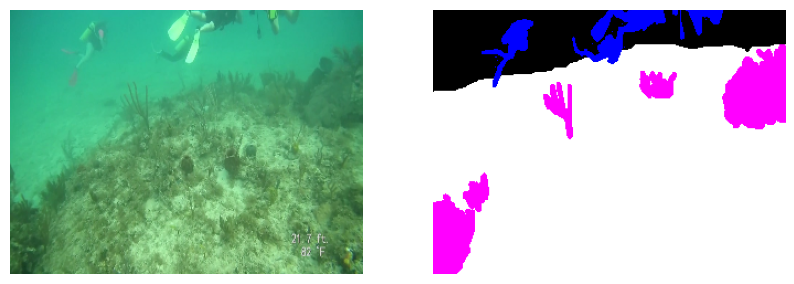

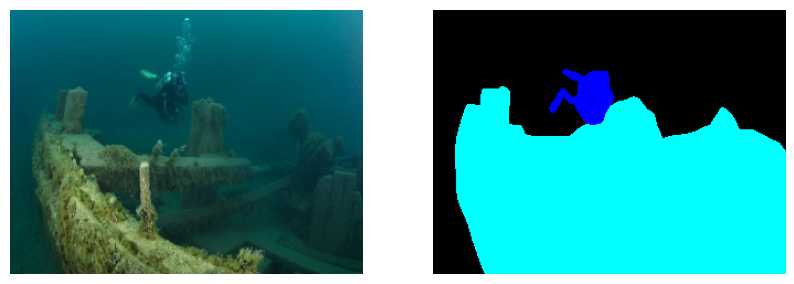

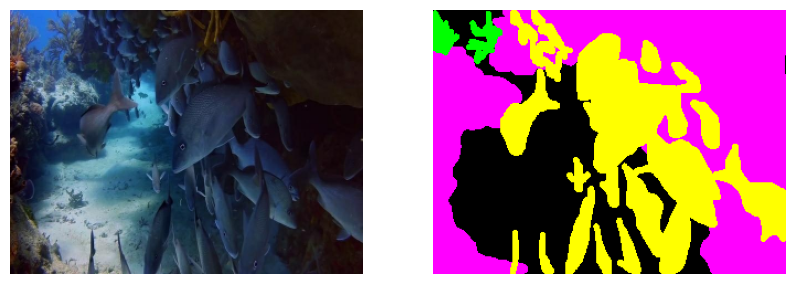

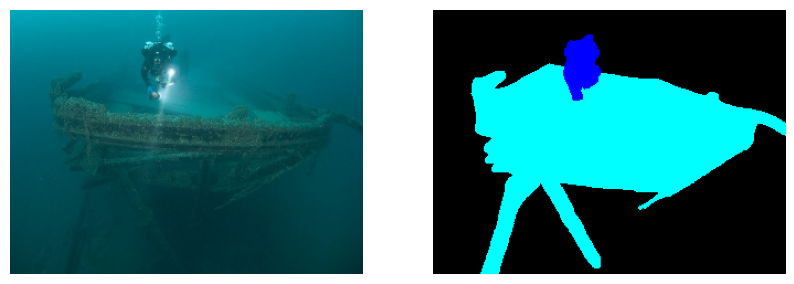

In [6]:
for code, name, weight in zip(class_to_color.keys(), CLASS_NAMES, class_weights):
    print(f'Class {code}: {name} [weight = {weight}]')
print()

try:
    print('Number of batches in training set:', len(train_ds))
except TypeError:
    print('Training set is repeated indefinitely.')
print('Number of batches in validation set:', len(val_ds))
print('Number of batches in test set:', len(test_ds))
print()

data_batch = next(iter(val_ds))
images, masks = data_batch
print('Image batch shape:', images.shape)
print('Mask batch shape:', masks.shape)

reshaped = np.reshape(masks, (-1, 3))
mask_pixels = np.unique(reshaped, axis=0)
print('Unique mask pixels:\n', mask_pixels)

# Show some iamge-mask pairs for sanity check
for i, (img, mask) in enumerate(zip(images, masks)):
    if i > 4: break
    visualize_pair(img, mask, mask_type='one-hot')

## Training

In [32]:
def iou_index(y_true, y_pred, smooth=1):
    intersection = K.sum(K.abs(y_true * y_pred), axis=[1, 2, 3])
    union = K.sum(y_true, axis=[1, 2, 3]) + K.sum(y_pred, axis=[1, 2, 3]) - intersection
    iou = K.mean((intersection + smooth) / (union + smooth), axis=0)
    return iou


def f_score(y_true, y_pred, smooth=1):
    intersection = K.sum(y_true * y_pred, axis=[1, 2, 3])
    union = K.sum(y_true, axis=[1, 2, 3]) + K.sum(y_pred, axis=[1, 2, 3])
    dice = K.mean((2. * intersection + smooth) / (union + smooth), axis=0)
    return dice


# IoU = Jaccard index
def jaccard_coef(y_true, y_pred, smooth: float = 1.0):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(K.abs(y_true_f * y_pred_f))
    union = K.sum(y_true_f) + K.sum(y_pred_f) - intersection
    return K.mean((intersection + smooth) / (union + smooth))


# f1 score = Dice coefficient
def dice_coef(y_true, y_pred, smooth: float = 1.0):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    area_true = K.sum(y_true_f)
    area_pred = K.sum(y_pred_f)
    return K.mean((2. * intersection + smooth) / (area_true + area_pred + smooth))


def jaccard_loss(y_true, y_pred):
    return 1.0 - jaccard_coef(y_true, y_pred)


def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)


def focal_loss(y_true, y_pred, gamma=2., alpha=4., epsilon=1.e-9):
    y_true_c = tf.convert_to_tensor(y_true, tf.float32)
    y_pred_c = tf.convert_to_tensor(y_pred, tf.float32)

    model_out = tf.add(y_pred_c, epsilon)
    ce = tf.multiply(y_true_c, -tf.math.log(model_out))
    weight = tf.multiply(y_true_c, tf.pow(tf.subtract(1., model_out), gamma))
    fl = tf.multiply(alpha, tf.multiply(weight, ce))

    reduced_fl = tf.reduce_max(fl, axis=-1)
    return tf.reduce_mean(reduced_fl)


def hybrid_loss(y_true, y_pred):
    j_loss = jaccard_loss(y_true, y_pred)
    d_loss = dice_loss(y_true, y_pred)
    f_loss = focal_loss(y_true, y_pred)
    return j_loss + d_loss + f_loss


class VisualizeProgress(tf.keras.callbacks.Callback):
    def __init__(self, test_data, every_n_epochs=10, num_samples=4,
                 threshold=None, deep_supervision=False, wandb_log=False):
        super(VisualizeProgress, self).__init__()
        self.test_data = test_data
        self.every_n_epochs = every_n_epochs
        self.num_samples = num_samples
        self.threshold = threshold
        self.deep_supervision = deep_supervision
        self.wandb_log = wandb_log

    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.every_n_epochs == 0:
            x_test, y_test = self.test_data
            predictions = self.model.predict(x_test[:self.num_samples])

            if self.deep_supervision:
                predictions = predictions[-1]

            plt.figure(figsize=(9, 12))
            for index in range(self.num_samples):
                if index >= len(x_test): break

                plt.subplot(self.num_samples, 3, index * 3 + 1)
                plt.imshow(x_test[index])
                if index == 0:
                    plt.title('Input Image')

                plt.subplot(self.num_samples, 3, index * 3 + 2)
                if self.threshold is None:
                    ground_truth = one_hot_to_rgb(y_test[index]).numpy() * 255
                else:
                    ground_truth = y_test[index]
                plt.imshow(ground_truth)
                if index == 0:
                    plt.title('Ground Truth')

                plt.subplot(self.num_samples, 3, index * 3 + 3)
                if self.threshold is None:
                    prediction = one_hot_to_rgb(predictions[index]).numpy() * 255
                else:
                    prediction = (predictions[index] > self.threshold).astype(np.uint8) * 255
                plt.imshow(prediction)
                if index == 0:
                    plt.title('Predicted Segmentation')

            if self.wandb_log:
                wandb.log({f'Segmentation results': wandb.Image(plt)})

            plt.tight_layout()
            plt.show()


In [33]:
# SM losses
sm_dice = sm.losses.DiceLoss(class_weights=class_weights)
sm_focal = sm.losses.CategoricalFocalLoss()
sm_cce = sm.losses.CategoricalCELoss(class_weights=class_weights)
sm_jac = sm.losses.JaccardLoss(class_weights=class_weights)
# sm_total_loss = (1. * sm_dice) + (3. * sm_focal) + (1. * sm_cce) + (1. * sm_jac)
sm_total_loss = (1. * sm_dice) + (3. * sm_focal)
# sm_total_loss = sm.losses.DiceLoss() + sm.losses.BinaryFocalLoss()

# SM metrics
sm_iou = sm.metrics.IOUScore(threshold=0.5)
sm_f1 = sm.metrics.FScore(threshold=0.5)

In [34]:
optimizer = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE, beta_1=MOMENTUM)
threshold = 0.5 if RGB_MODE else None
activation = 'sigmoid' if RGB_MODE else 'softmax'
loss = 'binary_crossentropy' if RGB_MODE else 'categorical_crossentropy'

model = UNet(
    input_shape=IMAGE_SHAPE,
    num_classes=3 if RGB_MODE else NUM_CLASSES,
    num_filters=32,
    dropout=DROPOUT,
    batchnorm=True,
    final_activation=activation,
)

model.compile(
    optimizer=optimizer,
    loss=loss,
    metrics=['accuracy', jaccard_coef, dice_coef, sm_iou, sm_f1],
)

tf.keras.utils.plot_model(model, show_shapes=True)
model.summary()

Model: "U-Net"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_7 (InputLayer)           [(None, 240, 320, 3  0           []                               
                                )]                                                                
                                                                                                  
 conv2d_115 (Conv2D)            (None, 240, 320, 32  896         ['input_7[0][0]']                
                                )                                                                 
                                                                                                  
 batch_normalization_109 (Batch  (None, 240, 320, 32  128        ['conv2d_115[0][0]']             
 Normalization)                 )                                                             

Epoch 1/3
1/1 [==============================] - 2s 2s/steploss: 2.4529 - accuracy: 0.1053 - jaccard_coef: 0.0643 - dice_coef: 


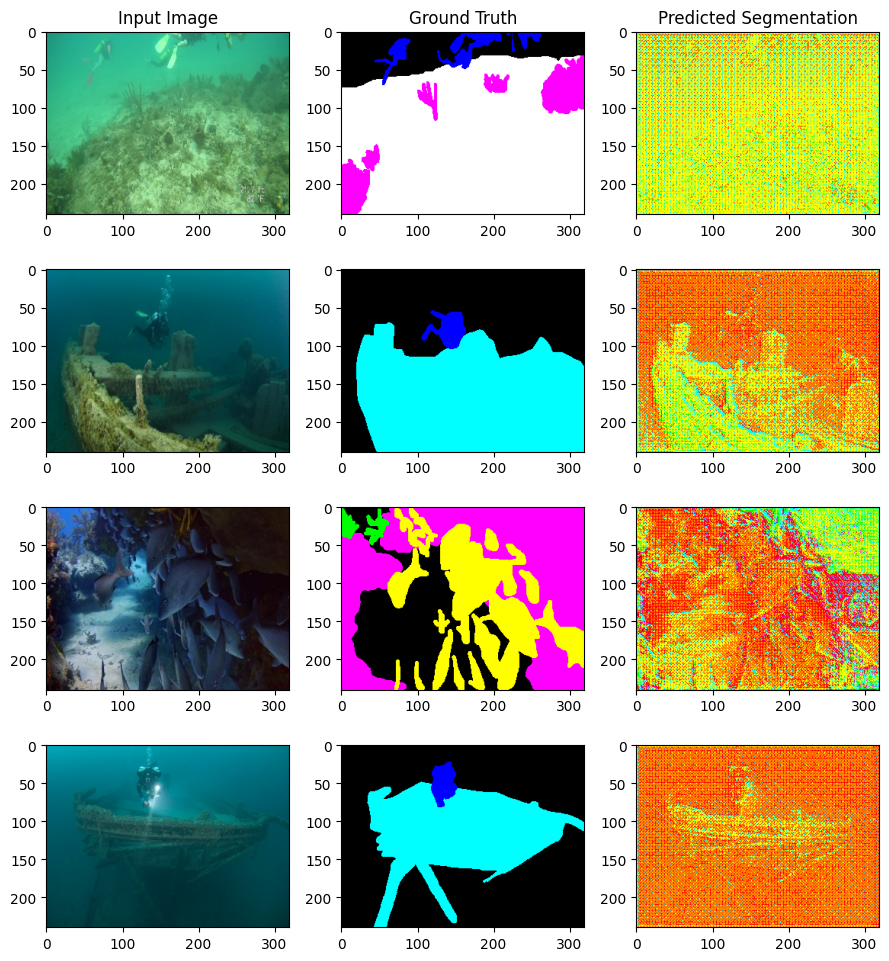

2/2 [==============================] - 49s 13s/step - loss: 2.4529 - accuracy: 0.1053 - jaccard_coef: 0.0643 - dice_coef: 0.1205 - iou_score: 0.0044 - f1-score: 0.0084 - val_loss: 2.4012 - val_accuracy: 0.0436 - val_jaccard_coef: 0.0534 - val_dice_coef: 0.1013 - val_iou_score: 0.2500 - val_f1-score: 0.2500 - lr: 3.0000e-04
Epoch 2/3
1/1 [==============================] - 2s 2s/steploss: 2.5559 - accuracy: 0.0695 - jaccard_coef: 0.0567 - dice_coef: 


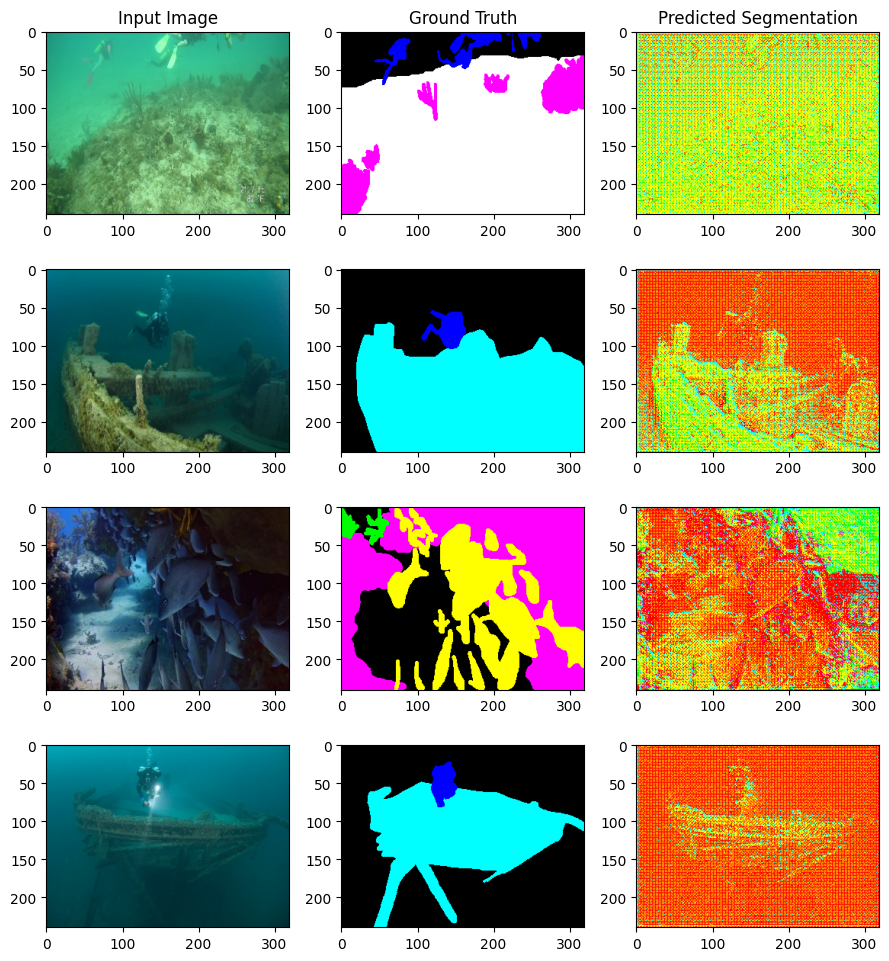

2/2 [==============================] - 47s 14s/step - loss: 2.5559 - accuracy: 0.0695 - jaccard_coef: 0.0567 - dice_coef: 0.1073 - iou_score: 0.0018 - f1-score: 0.0035 - val_loss: 2.3464 - val_accuracy: 0.0426 - val_jaccard_coef: 0.0553 - val_dice_coef: 0.1048 - val_iou_score: 0.2500 - val_f1-score: 0.2500 - lr: 3.0000e-04
Epoch 3/3


KeyboardInterrupt: 

In [35]:
# Smaller dataset for testing
EPOCHS = 3
STEPS_PER_EPOCH = 2
train_ds = train_ds.take(STEPS_PER_EPOCH)
val_ds = val_ds.take(STEPS_PER_EPOCH)

callbacks = [
    ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=5, verbose=1),
    EarlyStopping(monitor='val_loss', patience=10, verbose=1),
    VisualizeProgress(next(iter(val_ds)), every_n_epochs=1, num_samples=5, threshold=threshold),
]
if LOGGING:
    callbacks.append(WandbCallback())

history = model.fit(
    train_ds, validation_data=val_ds, validation_steps=len(val_ds),
    epochs=EPOCHS, steps_per_epoch=STEPS_PER_EPOCH,
    callbacks=callbacks, verbose=1,
)

In [ ]:
# Plot training history
plt.figure(figsize=(12, 8))

plt.subplot(221)
plt.title('Loss')
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.legend()

plt.subplot(222)
plt.title('Accuracy')
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.legend()

plt.subplot(223)
plt.title('Jaccard')
plt.plot(history.history['jaccard_coef'], label='train')
plt.plot(history.history['val_jaccard_coef'], label='val')
plt.legend()

plt.subplot(224)
plt.title('Dice')
plt.plot(history.history['dice_coef'], label='train')
plt.plot(history.history['val_dice_coef'], label='val')
plt.legend()

plt.tight_layout()
plt.savefig('training-history.png')
plt.show()

In [ ]:
# save model
model.save('models/basic-unet-model.h5')

In [ ]:
if LOGGING:
    wandb.finish()

## Evaluation

In [ ]:
# load model
model = tf.keras.models.load_model('models/basic-unet-model.h5', custom_objects={
    'jaccard_coef_loss': lambda y_true, y_pred: -jaccard_coef(y_true, y_pred),
    'jaccard_coef': jaccard_coef,
    'dice_coef': dice_coef,
})

In [ ]:
# load model for testing
model = tf.keras.models.load_model('models/sm-unet-model.h5', compile=False)

In [ ]:
test = next(iter(test_ds))

predictions = model.predict(test[0])
predictions.shape

In [ ]:
model.evaluate(test[0], test[1])